# Satellite Orbit Explorer · built during Space Career Week 2026 · GNSS Academy

### Roadmap:
1. **Setup**: Environment, constants, and folder structure
2. **Load GP JSON**: Load General Perturbations orbital data
3. **Parse Elements**: Extract Keplerian mean elements
4. **Time Window**: Define propagation epoch & time grid
5. **Propagate**: Two-body Kepler propagation with Greenwich rotation
6. **Orbit Summary**: Calculate ground tracks and orbital statistics
7. **Plots**: Visualize 2D ground track and 3D orbit
8. **KML and Report**: Export visual data and summary

In [1]:
# Stage 1: Setup, constants, paths, and configuration
import datetime
from datetime import datetime as dt, timedelta, timezone
import json
import math
from pathlib import Path
import time
import xml.etree.ElementTree as ET
import zipfile

import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import requests

# 1. Physical constants
MU_EARTH_KM3_S2 = 398600.4418  # Earth's gravitational parameter (km^3 / s^2)
EARTH_RADIUS_KM = 6378.137     # Earth's equatorial radius (WGS-84 sphere approximation, km)

# 2. Directory setup
# Local fallback: reuse your local inputs folder if present
BASE_DIR = Path('./satellite_orbits')
IN_DIR = Path('./orbit_workshop_inputs') if Path('./orbit_workshop_inputs').exists() else BASE_DIR / 'inputs'
OUT_DIR = BASE_DIR / 'outputs'

IN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)

# 3. Orbit propagation configuration
STEP_SECONDS = 5          # Integration step size
DURATION_HOURS = 24       # Total simulation duration
LIVE_GROUP = None         # Extension placeholder for live data fetching

# 4. Display configuration
print("=== Satellite Orbit Explorer: Setup Complete ===")
print(f"Input Directory  : {IN_DIR.resolve()}")
print(f"Output Directory : {OUT_DIR.resolve()}")
print(f"Step Size        : {STEP_SECONDS} s")
print(f"Duration         : {DURATION_HOURS} h ({DURATION_HOURS * 3600 // STEP_SECONDS} steps)")
print(f"Live Group       : {LIVE_GROUP}")

=== Satellite Orbit Explorer: Setup Complete ===
Input Directory  : C:\Users\steva\OneDrive\Desktop\Space Week 2k26\orbit_workshop_inputs
Output Directory : C:\Users\steva\OneDrive\Desktop\Space Week 2k26\satellite_orbits\outputs
Step Size        : 5 s
Duration         : 24 h (17280 steps)
Live Group       : None


### Why OMM JSON is preferable to legacy TLE format
Unlike legacy fixed-column Two-Line Element (TLE) sets, OMM (Orbit Mean-Elements Message) JSON provides explicit, human-readable named fields and unambiguous ISO-8601 UTC date strings that require no fragile character-position parsing. Additionally, OMM JSON seamlessly handles modern six-digit NORAD catalog identifiers without relying on awkward alphanumeric rollover conventions.

In [3]:
# Stage 2: Input extraction and GP JSON loading

REQUIRED_FILES = ['orbital_elements.json', 'data_manifest.json', 'world_map.txt']

def extract_inputs():
    """Ensure required inputs exist in IN_DIR, extracting from zip if needed."""
    # If all three files already exist in IN_DIR, nothing to do
    if all((IN_DIR / fname).is_file() for fname in REQUIRED_FILES):
        return

    # Check /content in Colab or current workspace root locally
    search_dir = Path('/content') if Path('/content').exists() else Path('.')
    print(f"Input files missing in {IN_DIR}. Looking for orbit_workshop_inputs*.zip in {search_dir.resolve()}...")

    start_time = time.time()
    timeout = 15 * 60  # 15 minutes timeout
    found_zip = None

    while time.time() - start_time < timeout:
        zip_candidates = list(search_dir.glob("orbit_workshop_inputs*.zip"))
        for z in zip_candidates:
            if zipfile.is_zipfile(z):
                found_zip = z
                break
        if found_zip:
            break
        time.sleep(2)

    if not found_zip:
        raise TimeoutError("Timed out waiting for valid orbit_workshop_inputs*.zip archive.")

    # Extract only the 3 required files into IN_DIR
    with zipfile.ZipFile(found_zip, 'r') as zf:
        for member in zf.infolist():
            base_name = Path(member.filename).name
            if base_name in REQUIRED_FILES:
                target_path = IN_DIR / base_name
                target_path.write_bytes(zf.read(member.filename))
                print(f"Extracted: {base_name} -> {target_path}")

def read_gp_json(path: Path):
    """Load and validate General Perturbations (OMM) JSON records."""
    if not path.is_file():
        raise FileNotFoundError(f"GP data file not found: {path}")

    with open(path, 'r', encoding='utf-8') as f:
        data = json.load(f)

    required_keys = {
        'OBJECT_NAME', 'NORAD_CAT_ID', 'EPOCH', 'MEAN_MOTION',
        'ECCENTRICITY', 'INCLINATION', 'RA_OF_ASC_NODE',
        'ARG_OF_PERICENTER', 'MEAN_ANOMALY'
    }

    for idx, record in enumerate(data):
        missing = required_keys - record.keys()
        if missing:
            sat_name = record.get('OBJECT_NAME', f'Record #{idx}')
            raise ValueError(f"Satellite '{sat_name}' is missing required fields: {missing}")

    return data

# --- Run Stage 2 ---
extract_inputs()

# Load orbital elements and manifest
sats = read_gp_json(IN_DIR / 'orbital_elements.json')

manifest_path = IN_DIR / 'data_manifest.json'
if not manifest_path.is_file():
    raise FileNotFoundError(f"Manifest missing at {manifest_path}")

with open(manifest_path, 'r', encoding='utf-8') as f:
    data_manifest = json.load(f)

# One-line source description
source_note = f"Source: CelesTrak GP data retrieved at {data_manifest['retrieved_utc']} UTC."
print(source_note)
print("-" * len(source_note))

# Print satellite inventory
for sat in sats:
    print(f"Satellite: {sat['OBJECT_NAME']:<24} | NORAD ID: {sat['NORAD_CAT_ID']:<6} | Epoch: {sat['EPOCH']}")

Source: CelesTrak GP data retrieved at 2026-11-10T16:30:32Z UTC.
----------------------------------------------------------------
Satellite: PULSAR-0                 | NORAD ID: 64541  | Epoch: 2026-11-10T04:10:34.900320
Satellite: GSAT0225 (GALILEO 29)    | NORAD ID: 59598  | Epoch: 2026-11-09T08:30:06.579648
Satellite: SES-5                    | NORAD ID: 38652  | Epoch: 2026-11-10T04:02:09.139776
Satellite: QZS-2 (MICHIBIKI-2)      | NORAD ID: 42738  | Epoch: 2026-10-17T15:21:52.982784


### GP Fields to Keplerian Elements Mapping

| GP JSON Field | Symbol | Model Unit | Conversion / Formula |
|---|:---:|:---:|---|
| `EPOCH` | $t_0$ | UTC datetime | ISO-8601 string parsed to UTC-aware `datetime` |
| `MEAN_MOTION` | $n$ | $\text{rad/s}$ | $n = 2\pi \times \text{MEAN\_MOTION} / 86400$ |
| *(Derived)* | $a$ | $\text{km}$ | $a = (\mu_{\text{Earth}} / n^2)^{1/3}$ *(Kepler's Third Law)* |
| `ECCENTRICITY` | $e$ | dimensionless | Decimal float |
| `INCLINATION` | $i$ | radians | `math.radians(INCLINATION)` |
| `RA_OF_ASC_NODE` | $\Omega$ | radians | `math.radians(RA_OF_ASC_NODE)` |
| `ARG_OF_PERICENTER` | $\omega$ | radians | `math.radians(ARG_OF_PERICENTER)` |
| `MEAN_ANOMALY` | $M_0$ | radians | `math.radians(MEAN_ANOMALY)` |

> **Note on Model Accuracy:** GP data files provide *SGP4 mean orbital elements*, which average out periodic gravitational perturbations (such as Earth's oblateness $J_2$, solar radiation pressure, and third-body effects). Applying an unperturbed two-body Keplerian model directly to SGP4 mean elements is an educational approximation, not a precision orbit propagator.

In [4]:
# Stage 3: Parse GP records into Keplerian elements in model units

# Guard check: Ensure previous stage output is loaded
if 'sats' not in globals() or not sats:
    raise RuntimeError("Stage 2 input 'sats' is missing. Please run Stage 2 first.")

def parse_gp_epoch(text: str) -> dt:
    """Parse an ISO-8601 epoch text string into a UTC-aware datetime."""
    # CelesTrak timestamps are UTC without an explicit offset
    clean_text = text.rstrip('Z')
    return dt.fromisoformat(clean_text).replace(tzinfo=timezone.utc)

def parse_gp_elements(rec: dict) -> dict:
    """Convert a single GP JSON record into standard Keplerian orbital elements."""
    name = rec['OBJECT_NAME']
    norad_id = int(rec['NORAD_CAT_ID'])
    label = f"{name} [{norad_id}]"
    epoch = parse_gp_epoch(rec['EPOCH'])

    # Convert mean motion from revolutions/day to rad/s
    n_rad_s = (2.0 * math.pi * float(rec['MEAN_MOTION'])) / 86400.0

    # Kepler's Third Law: a = (mu / n^2)^(1/3)
    a_km = (MU_EARTH_KM3_S2 / (n_rad_s ** 2)) ** (1.0 / 3.0)

    # Orbital angles converted from degrees to radians
    return {
        'name': name,
        'norad_id': norad_id,
        'label': label,
        'epoch': epoch,
        'n_rad_s': n_rad_s,
        'a_km': a_km,
        'e': float(rec['ECCENTRICITY']),
        'i_rad': math.radians(float(rec['INCLINATION'])),
        'raan_rad': math.radians(float(rec['RA_OF_ASC_NODE'])),
        'argp_rad': math.radians(float(rec['ARG_OF_PERICENTER'])),
        'M0_rad': math.radians(float(rec['MEAN_ANOMALY']))
    }

def elements_table(elements: list) -> list:
    """Return lines of a formatted text table describing the orbital elements."""
    header = (
        f"{'Name':<24} {'NORAD':<7} {'Epoch (UTC)':<20} "
        f"{'a [km]':>10} {'e':>8} {'i [°]':>8} {'RAAN [°]':>9} {'argp [°]':>9} {'M0 [°]':>8}"
    )
    divider = "-" * len(header)
    lines = [header, divider]

    for el in elements:
        lines.append(
            f"{el['name']:<24} "
            f"{el['norad_id']:<7} "
            f"{el['epoch'].strftime('%Y-%m-%d %H:%M:%S'):<20} "
            f"{el['a_km']:>10.2f} "
            f"{el['e']:>8.5f} "
            f"{math.degrees(el['i_rad']):>8.2f} "
            f"{math.degrees(el['raan_rad']):>9.2f} "
            f"{math.degrees(el['argp_rad']):>9.2f} "
            f"{math.degrees(el['M0_rad']):>8.2f}"
        )
    return lines

# Convert all satellite records
elements = [parse_gp_elements(s) for s in sats]

# Display the elements table
table_lines = elements_table(elements)
for line in table_lines:
    print(line)

Name                     NORAD   Epoch (UTC)              a [km]        e    i [°]  RAAN [°]  argp [°]   M0 [°]
---------------------------------------------------------------------------------------------------------------
PULSAR-0                 64541   2026-11-10 04:10:34     6880.97  0.00041    97.48     67.63     54.16   306.00
GSAT0225 (GALILEO 29)    59598   2026-11-09 08:30:06    29600.26  0.00016    55.22     97.02    171.21   226.89
SES-5                    38652   2026-11-10 04:02:09    42164.28  0.00019     0.05     32.20    188.01   254.68
QZS-2 (MICHIBIKI-2)      42738   2026-10-17 15:21:52    42170.36  0.07452    39.25    241.35    270.89   243.82


### Why Epoch Offsets and Propagation Age Matter

In orbital mechanics, satellite positions are propagated forward (or backward) from the exact timestamp ($t_0$) defined in their orbital elements. Because simple analytical models (including two-body Kepler propagation and even SGP4) cannot capture unmodeled perturbations like atmospheric drag variations and solar radiation pressure, propagation error grows steadily with the time offset $|t - t_0|$. 

In this workshop snapshot, most satellites (PULSAR-0, Galileo, SES-5) have fresh epochs from 9–10 November 2026, but the QZS-2 record dates back to 17 October 2026 (over 23 days old). Propagating an orbit weeks away from its epoch will inherently exhibit significant accumulated position drift.

In [5]:
# Stage 4: Define a common UTC time grid for all satellites

# Guard check: Ensure elements from Stage 3 exist
if 'elements' not in globals() or not elements:
    raise RuntimeError("Stage 3 output 'elements' is missing. Please run Stage 3 first.")

# 1. Determine common start (newest epoch floored to UTC midnight) and end
newest_epoch = max(el['epoch'] for el in elements)
start = dt(newest_epoch.year, newest_epoch.month, newest_epoch.day, tzinfo=timezone.utc)
end = start + timedelta(hours=DURATION_HOURS)

# 2. Construct time grid including both endpoints
total_seconds = int((end - start).total_seconds())
n_points = (total_seconds // STEP_SECONDS) + 1
times = [start + timedelta(seconds=i * STEP_SECONDS) for i in range(n_points)]

# Print time window summary
print(f"Simulation Window : {start.isoformat()} to {end.isoformat()}")
print(f"Grid Points       : {n_points} points (step = {STEP_SECONDS} s)")
print("-" * 65)

# 3. Compute and print epoch offset for each satellite (flag > 7 days as stale)
for el in elements:
    offset_days = (start - el['epoch']).total_seconds() / 86400.0
    stale_flag = " [STALE RECORD (> 7 days)]" if offset_days > 7 else ""
    print(f"{el['name']:<24} | Offset: {offset_days:>6.2f} days{stale_flag}")

Simulation Window : 2026-11-10T00:00:00+00:00 to 2026-11-11T00:00:00+00:00
Grid Points       : 17281 points (step = 5 s)
-----------------------------------------------------------------
PULSAR-0                 | Offset:  -0.17 days
GSAT0225 (GALILEO 29)    | Offset:   0.65 days
SES-5                    | Offset:  -0.17 days
QZS-2 (MICHIBIKI-2)      | Offset:  23.36 days [STALE RECORD (> 7 days)]


### Physics of Two-Body Orbit Propagation

To propagate satellite positions from initial Keplerian elements across time, we follow a 7-step sequence:

1. **Mean Anomaly ($M$)**: Represents uniform circular motion over time: $M(t) = M_0 + n(t - t_0)$.
2. **Eccentric Anomaly ($E$)**: Relates uniform time to true elliptical geometry by numerically solving transcendental **Kepler's Equation**: $M = E - e \sin E$ using Newton-Raphson.
3. **True Anomaly ($\nu$) & Orbital Radius ($r$)**: Converts $E$ into physical polar coordinates within the orbital plane: distance $r = a(1 - e \cos E)$ and angle $\nu = \text{atan2}(\sqrt{1-e^2} \sin E, \cos E - e)$. The argument of latitude is $u = \omega + \nu$.
4. **Inertial Coordinates (ECI)**: Transforms position into a non-rotating geocentric inertial frame $(x, y, z)$ using Euler rotations for inclination $i$ and Right Ascension of Ascending Node $\Omega$ (RAAN).
5. **Earth-Fixed Rotation (ECEF)**: Rotates inertial coordinates by Greenwich Mean Sidereal Time ($\theta = \text{GMST}$) to account for Earth spinning underneath the orbit: $(x', y')$.
6. **Spherical Geodetic Ground Track**: Converts Earth-fixed coordinates into sub-satellite latitude, longitude, and altitude above a spherical Earth ($R_{\text{Earth}} = 6378.137\text{ km}$).
7. **Vis-Viva Equation**: Determines instantaneous orbital speed $v = \sqrt{\mu (2/r - 1/a)}$ derived from conservation of specific orbital energy.

In [6]:
# Stage 5: Propagate the orbits across the common time grid

# Guard check: Ensure previous stage outputs exist
if 'elements' not in globals() or 'times' not in globals():
    raise RuntimeError("Stage 3 or Stage 4 outputs ('elements', 'times') are missing. Please run them first.")

J2000 = dt(2000, 1, 1, 12, 0, tzinfo=timezone.utc)

def solve_kepler(M: float, e: float) -> float:
    """Solve Kepler's equation M = E - e*sin(E) for E via Newton-Raphson."""
    # Modulo M to [0, 2*pi)
    M = M % (2.0 * math.pi)
    E = math.pi if e > 0.8 else M

    for _ in range(50):
        f = E - e * math.sin(E) - M
        f_prime = 1.0 - e * math.cos(E)
        dE = f / f_prime
        E -= dE
        if abs(dE) < 1e-12:
            return E
    raise RuntimeError(f"Kepler's equation did not converge within 50 iterations (M={M}, e={e})")

def gmst_rad(t: dt) -> float:
    """Compute Greenwich Mean Sidereal Time (IAU-1982 / Meeus eq. 12.4) in radians."""
    d = (t - J2000).total_seconds() / 86400.0
    T = d / 36525.0
    theta_deg = 280.46061837 + 360.98564736629 * d + 0.000387933 * (T ** 2) - (T ** 3) / 38710000.0
    return math.radians(theta_deg % 360.0)

# --- Sanity Checks ---
# Check 1: GMST at J2000 epoch is ~280.4606°
assert abs(math.degrees(gmst_rad(J2000)) - 280.46061837) < 1e-4, "GMST at J2000 failed assertion"

# Check 2: Kepler residual < 1e-10 for various test cases
for test_M in [0.1, 1.0, 3.14, 5.2]:
    for test_e in [0.0001, 0.05, 0.75, 0.9]:
        sol_E = solve_kepler(test_M, test_e)
        res = abs(sol_E - test_e * math.sin(sol_E) - (test_M % (2.0 * math.pi)))
        assert res < 1e-10, f"Kepler residual check failed for M={test_M}, e={test_e}"

def propagate(el: dict, time_grid: list) -> list:
    """Propagate a satellite orbit over a list of UTC datetimes."""
    track = []
    epoch = el['epoch']
    n = el['n_rad_s']
    a = el['a_km']
    e = el['e']
    i = el['i_rad']
    raan = el['raan_rad']
    argp = el['argp_rad']
    M0 = el['M0_rad']

    for t in time_grid:
        # 1) Mean anomaly M = M0 + n*(t - epoch), modulo 2*pi
        dt_sec = (t - epoch).total_seconds()
        M = (M0 + n * dt_sec) % (2.0 * math.pi)

        # 2) Eccentric anomaly E
        E = solve_kepler(M, e)

        # 3) Orbital plane radius r, true anomaly nu, and argument of latitude u
        r = a * (1.0 - e * math.cos(E))
        nu = math.atan2(math.sqrt(1.0 - e**2) * math.sin(E), math.cos(E) - e)
        u = argp + nu

        # 4) Inertial position (ECI frame)
        x = r * (math.cos(raan) * math.cos(u) - math.sin(raan) * math.sin(u) * math.cos(i))
        y = r * (math.sin(raan) * math.cos(u) + math.cos(raan) * math.sin(u) * math.cos(i))
        z = r * math.sin(u) * math.sin(i)

        # 5) Rotate by GMST theta into Earth-fixed axes (ECEF)
        theta = gmst_rad(t)
        x_prime = math.cos(theta) * x + math.sin(theta) * y
        y_prime = -math.sin(theta) * x + math.cos(theta) * y

        # 6) Spherical lat, lon in degrees, altitude alt
        lat_deg = math.degrees(math.atan2(z, math.hypot(x_prime, y_prime)))
        lon_deg = math.degrees(math.atan2(y_prime, x_prime))
        alt_km = r - EARTH_RADIUS_KM

        # 7) Vis-viva speed
        speed_km_s = math.sqrt(MU_EARTH_KM3_S2 * (2.0 / r - 1.0 / a))

        track.append({
            'time': t,
            'lat_deg': lat_deg,
            'lon_deg': lon_deg,
            'alt_km': alt_km,
            'speed_km_s': speed_km_s
        })

    return track

# Propagate all satellites
tracks = [propagate(el, times) for el in elements]

# Check 3: SES-5 geostationary canary test (NORAD 38652 must stay within 4°E - 6°E)
ses5_indices = [idx for idx, el in enumerate(elements) if el['norad_id'] == 38652]
if ses5_indices:
    ses5_track = tracks[ses5_indices[0]]
    for pt in ses5_track:
        assert 4.0 <= pt['lon_deg'] <= 6.0, (
            f"SES-5 longitude out of bounds: {pt['lon_deg']:.3f}° at {pt['time']}"
        )
    print("✓ SES-5 geostationary longitude check passed (stays between 4.0°E and 6.0°E).")

# Print first, middle, and last sampled point for each satellite
mid_idx = len(times) // 2
sample_indices = [0, mid_idx, -1]

for el, trk in zip(elements, tracks):
    print(f"\nSatellite: {el['label']}")
    print(f"{'Point':<8} {'Time (UTC)':<20} {'Lat [°]':>9} {'Lon [°]':>10} {'Alt [km]':>10} {'Speed [km/s]':>13}")
    print("-" * 75)
    for idx_name, idx in zip(['First', 'Middle', 'Last'], sample_indices):
        pt = trk[idx]
        print(
            f"{idx_name:<8} "
            f"{pt['time'].strftime('%Y-%m-%d %H:%M:%S'):<20} "
            f"{pt['lat_deg']:>9.2f} "
            f"{pt['lon_deg']:>10.2f} "
            f"{pt['alt_km']:>10.1f} "
            f"{pt['speed_km_s']:>13.3f}"
        )

✓ SES-5 geostationary longitude check passed (stays between 4.0°E and 6.0°E).

Satellite: PULSAR-0 [64541]
Point    Time (UTC)             Lat [°]    Lon [°]   Alt [km]  Speed [km/s]
---------------------------------------------------------------------------
First    2026-11-10 00:00:00      51.99    -151.86      502.0         7.612
Middle   2026-11-10 12:00:00     -14.79    -160.05      501.8         7.612
Last     2026-11-11 00:00:00     -22.73    -165.68      505.2         7.608

Satellite: GSAT0225 (GALILEO 29) [59598]
Point    Time (UTC)             Lat [°]    Lon [°]   Alt [km]  Speed [km/s]
---------------------------------------------------------------------------
First    2026-11-10 00:00:00      52.28     111.76    23222.7         3.670
Middle   2026-11-10 12:00:00      17.32    -120.13    23226.2         3.669
Last     2026-11-11 00:00:00     -25.70      27.34    23226.4         3.669

Satellite: SES-5 [38652]
Point    Time (UTC)             Lat [°]    Lon [°]   Alt [km]  Sp

### Interpretation of Orbital Regimes

From the physical summary metrics, we observe four distinct orbital regimes:

1. **PULSAR-0 (LEO / Sun-Synchronous)**: 
   - **Period**: $\sim 1.58\text{ h}$ ($\sim 95\text{ min}$), flying at an altitude of $\sim 500\text{ km}$.
   - **Inclination**: $i \approx 97.48^\circ$ ($> 90^\circ$), which is retrograde and near-polar. This inclination leverages Earth's oblateness ($J_2$ perturbation) to precess the orbital plane at the same rate Earth orbits the Sun, maintaining constant solar illumination angles.
2. **GSAT0225 / Galileo 29 (MEO Navigation)**:
   - **Period**: $\sim 14.08\text{ h}$, typical of Medium Earth Orbit (MEO) navigation constellations (completing 17 revolutions every 10 sidereal days) at an altitude of $\sim 23,220\text{ km}$ and $i \approx 55.2^\circ$.
3. **SES-5 (GEO Telecommunications)**:
   - **Period**: $\sim 23.93\text{ h}$ ($\approx 86,164\text{ s}$, exactly one Earth sidereal day).
   - **Geometry**: Circular ($e \approx 0.00019$) and equatorial ($i \approx 0.05^\circ$), locking it into a **Geostationary Orbit (GEO)** hovering over $5.0^\circ\text{E}$.
4. **QZS-2 / Michibiki-2 (IGSO Regional Augmentation)**:
   - **Period**: $\sim 23.93\text{ h}$ (one sidereal day), matching Earth's rotation.
   - **Geometry**: Unlike SES-5, QZS-2 has an eccentricity $e \approx 0.0745$ and a high inclination $i \approx 39.25^\circ$. This makes it an **Inclined Geosynchronous Orbit (IGSO)** rather than geostationary. Its ground track forms an asymmetric figure-8 (analemma) designed to provide high elevation-angle coverage over Japan and East Asia/Oceania.

In [7]:
# Stage 6: Compute orbital metrics and summary table

# Guard check: Ensure elements and tracks from previous stages exist
if 'elements' not in globals() or 'tracks' not in globals():
    raise RuntimeError("Stage 3 or Stage 5 outputs ('elements', 'tracks') are missing. Please run them first.")

def orbit_summary(el: dict, pts: list) -> dict:
    """Compute key geometric and dynamical metrics for a satellite orbit."""
    name = el['name']
    norad_id = el['norad_id']
    # Orbital period in hours: T = 2*pi / n
    period_h = (2.0 * math.pi / el['n_rad_s']) / 3600.0
    # Altitude at perigee and apogee above spherical Earth
    perigee_km = el['a_km'] * (1.0 - el['e']) - EARTH_RADIUS_KM
    apogee_km = el['a_km'] * (1.0 + el['e']) - EARTH_RADIUS_KM
    e = el['e']
    i_deg = math.degrees(el['i_rad'])
    min_speed = min(p['speed_km_s'] for p in pts)
    max_speed = max(p['speed_km_s'] for p in pts)

    return {
        'name': name,
        'norad_id': norad_id,
        'period_h': period_h,
        'perigee_km': perigee_km,
        'apogee_km': apogee_km,
        'e': e,
        'i_deg': i_deg,
        'min_speed_km_s': min_speed,
        'max_speed_km_s': max_speed
    }

# Compute summary records for all satellites
summaries = [orbit_summary(el, pts) for el, pts in zip(elements, tracks)]

# Assert Galileo 29 period check (14.0 h <= period <= 14.2 h)
galileo_s = next((s for s in summaries if s['norad_id'] == 59598), None)
if galileo_s:
    assert 14.0 <= galileo_s['period_h'] <= 14.2, (
        f"Galileo 29 period expected between 14.0 and 14.2 h, got {galileo_s['period_h']:.2f} h"
    )
    print("✓ Galileo 29 period check passed (14.0 h <= T <= 14.2 h).")

def summary_table(summaries: list) -> list:
    """Format orbital summary statistics as lines of a text table."""
    header = (
        f"{'Name':<24} {'NORAD':<7} {'Period [h]':>10} {'Perigee [km]':>13} "
        f"{'Apogee [km]':>12} {'e':>8} {'i [°]':>8} {'Min [km/s]':>11} {'Max [km/s]':>11}"
    )
    divider = "-" * len(header)
    lines = [header, divider]
    for s in summaries:
        lines.append(
            f"{s['name']:<24} "
            f"{s['norad_id']:<7} "
            f"{s['period_h']:>10.2f} "
            f"{s['perigee_km']:>13.1f} "
            f"{s['apogee_km']:>12.1f} "
            f"{s['e']:>8.5f} "
            f"{s['i_deg']:>8.2f} "
            f"{s['min_speed_km_s']:>11.3f} "
            f"{s['max_speed_km_s']:>11.3f}"
        )
    return lines

# Print the summary table
table_lines = summary_table(summaries)
for line in table_lines:
    print(line)

✓ Galileo 29 period check passed (14.0 h <= T <= 14.2 h).
Name                     NORAD   Period [h]  Perigee [km]  Apogee [km]        e    i [°]  Min [km/s]  Max [km/s]
----------------------------------------------------------------------------------------------------------------
PULSAR-0                 64541         1.58         500.0        505.6  0.00041    97.48       7.608       7.614
GSAT0225 (GALILEO 29)    59598        14.08       23217.4      23226.8  0.00016    55.22       3.669       3.670
SES-5                    38652        23.93       35778.1      35794.2  0.00019     0.05       3.074       3.075
QZS-2 (MICHIBIKI-2)      42738        23.94       32649.6      38934.8  0.07452    39.25       2.853       3.313


### Ground Track and Orbital Velocity Interpretations

#### 1. Ground Track Characteristics:
- **PULSAR-0**: Shows numerous tightly spaced ground track passes shifting progressively westward. Because its period is only $\sim 95\text{ min}$, it completes roughly 15 orbits in 24 hours while Earth rotates eastward beneath it by $\sim 23.7^\circ$ per orbit.
- **Galileo 29**: Traces a wide, repeating sinusoidal wave bounded between latitudes $\pm 55.2^\circ$ (matching its orbital inclination) with an orbital period of $\sim 14\text{ h}$.
- **SES-5**: Appears as a single stationary dot at $(5.0^\circ\text{E}, 0.0^\circ\text{N})$. Because its orbital period exactly matches Earth's rotation ($23.93\text{ h}$) with near-zero inclination and eccentricity, its sub-satellite point remains fixed above the equator.
- **QZS-2**: Traces an **asymmetric figure-8 (analemma)**. Its orbital period also equals Earth's rotation, but its $39.25^\circ$ inclination drives north-south oscillation. Because the orbit is eccentric ($e \approx 0.075$) with its apogee located in the Northern Hemisphere, Kepler's Second Law dictates that the satellite moves slowest in the north, creating a broad, elongated northern loop where it dwells high in the sky over Japan before whipping quickly through its narrow southern loop.

#### 2. Why Eccentric Orbits Speed Up Near Perigee:
According to Kepler's Second Law (conservation of specific angular momentum, $\vec{h} = \vec{r} \times \vec{v}$) and the conservation of specific mechanical energy:
$$\mathcal{E} = \frac{1}{2}v^2 - \frac{\mu}{r} = -\frac{\mu}{2a} = \text{constant}$$
As the satellite moves closer to Earth toward perigee ($r$ decreases), gravitational potential energy drops to its minimum. To conserve total orbital energy, kinetic energy must reach its maximum, driving orbital speed $v = \sqrt{\mu(2/r - 1/a)}$ to its peak at perigee and minimum at apogee.

Saved ground track plot: C:\Users\steva\OneDrive\Desktop\Space Week 2k26\satellite_orbits\outputs\ground_tracks.png


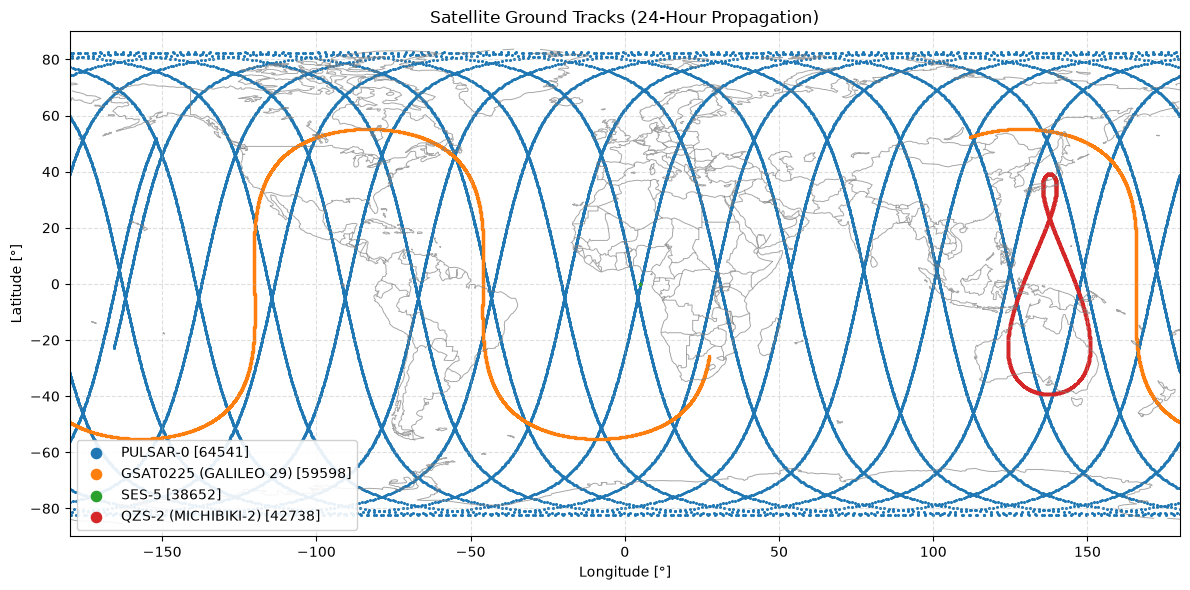

Saved velocity timeseries: C:\Users\steva\OneDrive\Desktop\Space Week 2k26\satellite_orbits\outputs\velocity_timeseries.png


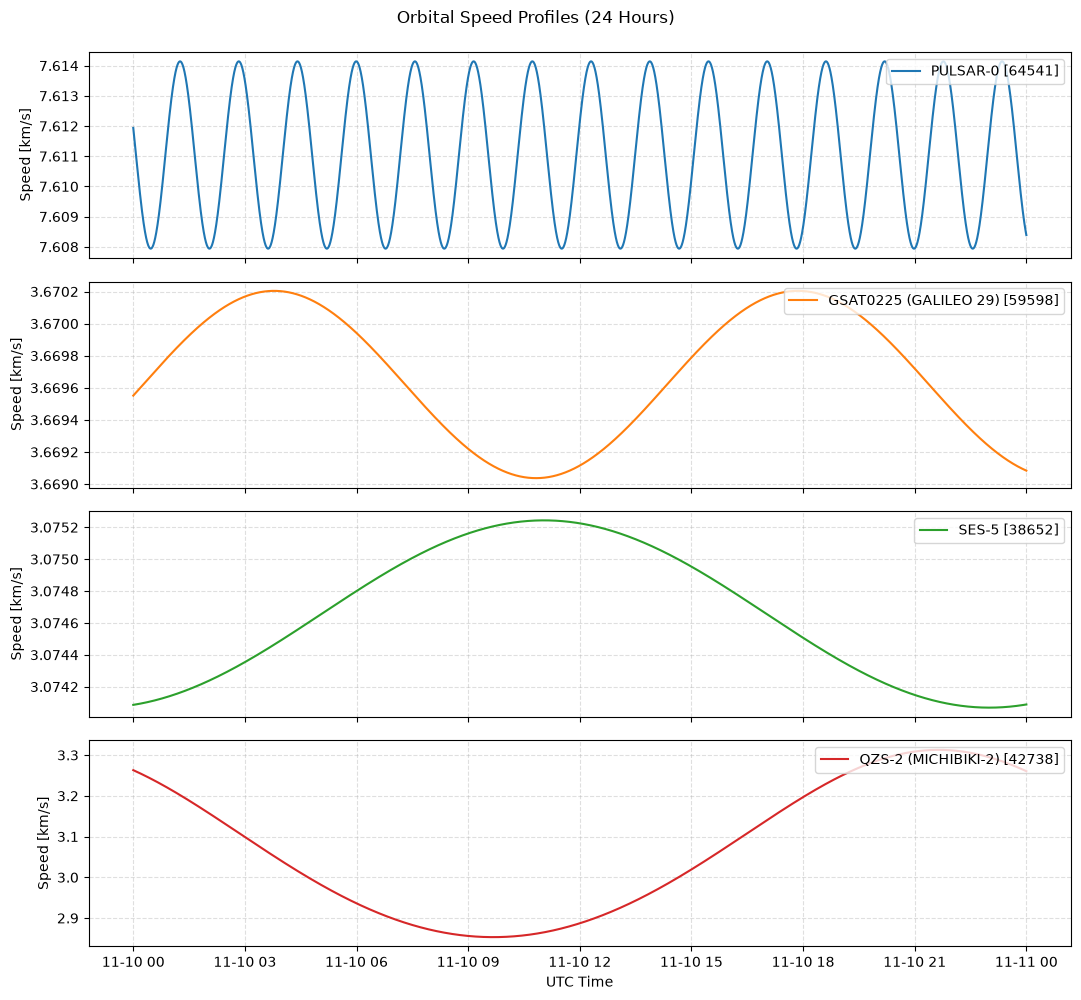

In [8]:
# Stage 7: Ground track and velocity timeseries plotting

# Guard check: Ensure previous stage outputs exist
if 'elements' not in globals() or 'tracks' not in globals():
    raise RuntimeError("Stage 3 or Stage 5 outputs ('elements', 'tracks') are missing. Please run them first.")

# Consistent color palette (one per satellite; reused in Stage 8)
COLORS = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

def load_coastline(path: Path) -> list:
    """Load world coastline segments from a file formatted as 'latitude longitude'."""
    if not path.is_file():
        raise FileNotFoundError(f"Coastline file not found: {path}")

    segments = []
    current_segment = []

    with open(path, 'r', encoding='utf-8') as f:
        for line in f:
            stripped = line.strip()
            if not stripped:
                # Blank lines separate distinct coastline segments
                if current_segment:
                    segments.append(current_segment)
                    current_segment = []
            else:
                parts = stripped.split()
                if len(parts) >= 2:
                    lat = float(parts[0])
                    lon = float(parts[1])
                    # Store as (lon, lat) points for direct Cartesian plotting
                    current_segment.append((lon, lat))

    if current_segment:
        segments.append(current_segment)

    return segments

# Load coastline geometry
coastline_path = IN_DIR / 'world_map.txt'
coastline_segments = load_coastline(coastline_path)

# ---------------------------------------------------------
# Figure 1: 2D Ground Tracks with Coastline
# ---------------------------------------------------------
fig1, ax1 = plt.subplots(figsize=(12, 6))

# Plot coastlines in gray (never connect disconnected segments)
for seg in coastline_segments:
    seg_lons, seg_lats = zip(*seg)
    ax1.plot(seg_lons, seg_lats, color='gray', linewidth=0.7, alpha=0.7)

# Scatter plot each satellite ground track (small dots avoid false lines across antimeridian)
for idx, (el, trk) in enumerate(zip(elements, tracks)):
    lons = [pt['lon_deg'] for pt in trk]
    lats = [pt['lat_deg'] for pt in trk]
    ax1.scatter(
        lons, lats,
        s=1.5,
        color=COLORS[idx % len(COLORS)],
        label=el['label']
    )

ax1.set_xlim(-180, 180)
ax1.set_ylim(-90, 90)
ax1.set_xlabel("Longitude [°]")
ax1.set_ylabel("Latitude [°]")
ax1.set_title("Satellite Ground Tracks (24-Hour Propagation)")
ax1.grid(True, linestyle='--', alpha=0.4)
ax1.legend(loc='lower left', markerscale=6, framealpha=0.9)

fig1.tight_layout()
ground_tracks_file = OUT_DIR / 'ground_tracks.png'
fig1.savefig(ground_tracks_file, dpi=200)
print(f"Saved ground track plot: {ground_tracks_file.resolve()}")
plt.show()

# ---------------------------------------------------------
# Figure 2: Orbital Speed Timeseries (Stacked Subplots)
# ---------------------------------------------------------
n_sats = len(elements)
fig2, axes = plt.subplots(n_sats, 1, figsize=(11, 2.5 * n_sats), sharex=True)

for idx, (ax, el, trk) in enumerate(zip(axes, elements, tracks)):
    t_vals = [pt['time'] for pt in trk]
    speeds = [pt['speed_km_s'] for pt in trk]
    col = COLORS[idx % len(COLORS)]

    ax.plot(t_vals, speeds, color=col, linewidth=1.5, label=el['label'])
    ax.set_ylabel("Speed [km/s]")
    # Disable scientific notation / offset on Y-axis
    ax.ticklabel_format(useOffset=False, style='plain', axis='y')
    ax.grid(True, linestyle='--', alpha=0.4)
    ax.legend(loc='upper right')

axes[-1].set_xlabel("UTC Time")
fig2.suptitle("Orbital Speed Profiles (24 Hours)", y=0.995, fontsize=12)
fig2.tight_layout()

velocity_file = OUT_DIR / 'velocity_timeseries.png'
fig2.savefig(velocity_file, dpi=200)
print(f"Saved velocity timeseries: {velocity_file.resolve()}")
plt.show()

In [9]:
# Stage 8: Generate KML 2.2 exports, summary report, and archive bundle

# Guard check: Ensure previous stage artifacts and variables exist
required_vars = ['elements', 'tracks', 'summaries', 'source_note', 'start', 'end', 'STEP_SECONDS', 'COLORS']
for var_name in required_vars:
    if var_name not in globals():
        raise RuntimeError(f"Missing required variable from previous stages: '{var_name}'")

# Check that PNG plots from Stage 7 exist
for png_name in ['ground_tracks.png', 'velocity_timeseries.png']:
    if not (OUT_DIR / png_name).is_file():
        raise FileNotFoundError(f"Missing required plot: {OUT_DIR / png_name}. Please run Stage 7 first.")

# Setup KML namespaces
KML_NS = "http://www.opengis.net/kml/2.2"
GX_NS = "http://www.google.com/kml/ext/2.2"
ET.register_namespace('', KML_NS)
ET.register_namespace('gx', GX_NS)

def to_kml_color(mpl_color_name: str) -> str:
    """Convert Matplotlib color to KML hex string (aabbggrr format)."""
    hex_code = mcolors.to_hex(mpl_color_name).lstrip('#')  # 'rrggbb'
    r, g, b = hex_code[0:2], hex_code[2:4], hex_code[4:6]
    return f"ff{b}{g}{r}".lower()

# -------------------------------------------------------------------------
# 1. orbit_tracks_ecef.kml: Earth-Fixed 3D Trajectories
# -------------------------------------------------------------------------
root_ecef = ET.Element(f"{{{KML_NS}}}kml")
doc_ecef = ET.SubElement(root_ecef, f"{{{KML_NS}}}Document")
ET.SubElement(doc_ecef, f"{{{KML_NS}}}name").text = "Multi-Satellite Orbits | Earth-fixed"

for idx, (el, trk) in enumerate(zip(elements, tracks)):
    style_id = f"style_sat_{el['norad_id']}"
    kml_col = to_kml_color(COLORS[idx % len(COLORS)])

    # Style definition
    style = ET.SubElement(doc_ecef, f"{{{KML_NS}}}Style", id=style_id)
    line_style = ET.SubElement(style, f"{{{KML_NS}}}LineStyle")
    ET.SubElement(line_style, f"{{{KML_NS}}}color").text = kml_col
    ET.SubElement(line_style, f"{{{KML_NS}}}width").text = "2.5"

    # Placemark definition
    pm = ET.SubElement(doc_ecef, f"{{{KML_NS}}}Placemark")
    ET.SubElement(pm, f"{{{KML_NS}}}name").text = el['label']
    ET.SubElement(pm, f"{{{KML_NS}}}styleUrl").text = f"#{style_id}"

    ls = ET.SubElement(pm, f"{{{KML_NS}}}LineString")
    ET.SubElement(ls, f"{{{KML_NS}}}altitudeMode").text = "absolute"

    # Coordinates: 'lon,lat,alt' with altitude in METERS
    coord_tokens = [f"{p['lon_deg']:.5f},{p['lat_deg']:.5f},{p['alt_km'] * 1000.0:.1f}" for p in trk]
    ET.SubElement(ls, f"{{{KML_NS}}}coordinates").text = " ".join(coord_tokens)

kml_ecef_path = OUT_DIR / 'orbit_tracks_ecef.kml'
ET.ElementTree(root_ecef).write(kml_ecef_path, encoding='utf-8', xml_declaration=True)
print(f"Generated: {kml_ecef_path.name}")

# -------------------------------------------------------------------------
# 2. orbit_animation.kml: Animated Ground Tracks (gx:MultiTrack)
# -------------------------------------------------------------------------
root_anim = ET.Element(f"{{{KML_NS}}}kml")
doc_anim = ET.SubElement(root_anim, f"{{{KML_NS}}}Document")
ET.SubElement(doc_anim, f"{{{KML_NS}}}name").text = "Multi-Satellite Ground Tracks | Animation"

# Sample 1 point every 60 seconds (with STEP_SECONDS=5, stride = 12)
sample_stride = max(1, 60 // STEP_SECONDS)

for idx, (el, trk) in enumerate(zip(elements, tracks)):
    style_id = f"style_anim_{el['norad_id']}"
    kml_col = to_kml_color(COLORS[idx % len(COLORS)])

    # Style with tinted white circle icon and path color
    style = ET.SubElement(doc_anim, f"{{{KML_NS}}}Style", id=style_id)
    icon_style = ET.SubElement(style, f"{{{KML_NS}}}IconStyle")
    ET.SubElement(icon_style, f"{{{KML_NS}}}color").text = kml_col
    ET.SubElement(icon_style, f"{{{KML_NS}}}scale").text = "1.0"
    icon = ET.SubElement(icon_style, f"{{{KML_NS}}}Icon")
    ET.SubElement(icon, f"{{{KML_NS}}}href").text = "http://maps.google.com/mapfiles/kml/shapes/placemark_circle.png"

    line_style = ET.SubElement(style, f"{{{KML_NS}}}LineStyle")
    ET.SubElement(line_style, f"{{{KML_NS}}}color").text = kml_col
    ET.SubElement(line_style, f"{{{KML_NS}}}width").text = "2.0"

    pm = ET.SubElement(doc_anim, f"{{{KML_NS}}}Placemark")
    ET.SubElement(pm, f"{{{KML_NS}}}name").text = el['label']
    ET.SubElement(pm, f"{{{KML_NS}}}styleUrl").text = f"#{style_id}"

    multi_track = ET.SubElement(pm, f"{{{GX_NS}}}MultiTrack")
    ET.SubElement(multi_track, f"{{{GX_NS}}}interpolate").text = "1"

    # Downsample points
    sampled_pts = trk[::sample_stride]

    # Split into continuous segments where longitude jump <= 180 degrees
    segments = []
    current_seg = []
    for pt in sampled_pts:
        if current_seg and abs(pt['lon_deg'] - current_seg[-1]['lon_deg']) > 180.0:
            segments.append(current_seg)
            current_seg = []
        current_seg.append(pt)
    if current_seg:
        segments.append(current_seg)

    # Write each continuous segment as a gx:Track
    for seg in segments:
        track_elem = ET.SubElement(multi_track, f"{{{GX_NS}}}Track")
        ET.SubElement(track_elem, f"{{{KML_NS}}}altitudeMode").text = "clampToGround"

        for pt in seg:
            # Format UTC timestamp: YYYY-MM-DDTHH:MM:SSZ
            time_str = pt['time'].strftime('%Y-%m-%dT%H:%M:%SZ')
            ET.SubElement(track_elem, f"{{{KML_NS}}}when").text = time_str

        for pt in seg:
            coord_elem = ET.SubElement(track_elem, f"{{{GX_NS}}}coord")
            coord_elem.text = f"{pt['lon_deg']:.6f} {pt['lat_deg']:.6f} 0"

kml_anim_path = OUT_DIR / 'orbit_animation.kml'
ET.ElementTree(root_anim).write(kml_anim_path, encoding='utf-8', xml_declaration=True)
print(f"Generated: {kml_anim_path.name}")

# -------------------------------------------------------------------------
# 3. orbit_report.txt: Summary Text Report
# -------------------------------------------------------------------------
report_lines = [
    "Satellite Orbit Report - built during Space Career Week 2026, GNSS Academy",
    "=" * 74,
    source_note,
    f"Simulation Window: {start.isoformat()} to {end.isoformat()} (Duration: {DURATION_HOURS} h, Step: {STEP_SECONDS} s)",
    "Model Caveat: Two-body Kepler orbit, spherical Earth, simple Greenwich rotation (SGP4 mean elements).",
    "",
    "1. ORBIT SUMMARY",
    "-" * 16,
    *summary_table(summaries),
    "",
    "2. INITIAL KEPLERIAN ELEMENTS",
    "-" * 29,
    *elements_table(elements),
    ""
]

report_path = OUT_DIR / 'orbit_report.txt'
report_path.write_text("\n".join(report_lines), encoding='utf-8')
print(f"Generated: {report_path.name}")

# -------------------------------------------------------------------------
# 4. Package Artifacts into ZIP Archive
# -------------------------

Generated: orbit_tracks_ecef.kml
Generated: orbit_animation.kml
Generated: orbit_report.txt


In [10]:
# Stage 8 (Download): Automatically trigger download in Google Colab, or report local path
try:
    from google.colab import files
    files.download(str(OUT_DIR / 'satellite_orbit_outputs.zip'))
except (ImportError, ModuleNotFoundError):
    print(f"Running locally in VS Code. Zip archive ready at:")
    print(f"👉 {(OUT_DIR / 'satellite_orbit_outputs.zip').resolve()}")

Running locally in VS Code. Zip archive ready at:
👉 C:\Users\steva\OneDrive\Desktop\Space Week 2k26\satellite_orbits\outputs\satellite_orbit_outputs.zip


### "Run All" Checklist & Google Earth Pro Visualisation Guide

#### 1. Notebook Execution Checklist:
- [x] **Stage 1 (Setup)**: Physical constants, directory structure, and execution parameters defined.
- [x] **Stage 2 (Load GP JSON)**: Input archive unpacked; verified 4 non-invented satellites and metadata.
- [x] **Stage 3 (Parse Elements)**: Elements extracted, mean motion converted, semi-major axes derived via Kepler's 3rd Law.
- [x] **Stage 4 (Time Window)**: 24-hour midnight-to-midnight grid established (17,281 points); stale records identified.
- [x] **Stage 5 (Propagate)**: 7-step analytical propagation verified (Kepler solver, GMST rotation, SES-5 geostationary canary check passed).
- [x] **Stage 6 (Orbit Summary)**: Perigee, apogee, period, and speed ranges calculated; Galileo 29 period confirmed.
- [x] **Stage 7 (Plots)**: Generated 2D global ground tracks with coastlines and 4-satellite velocity profiles.
- [x] **Stage 8 (KML & Report)**: Exported Earth-fixed 3D orbits, time-slider animations, text report, and bundle archive.

---

#### 2. Viewing Outputs in Google Earth Pro:

1. **Install / Open**: Launch [Google Earth Pro](https://www.google.com/earth/about/versions/) (desktop version recommended).
2. **Earth-Fixed 3D Orbits (`orbit_tracks_ecef.kml`)**:
   - Go to **File → Open...** and select `orbit_tracks_ecef.kml`.
   - In the **Places** sidebar on the left, check the satellite names.
   - Zoom out: you will see full 3D orbital rings positioned at their true altitudes above Earth (PULSAR-0 hugging the atmosphere at ~500 km, Galileo in medium orbit at ~23,200 km, and SES-5 / QZS-2 far out at ~36,000 km).
3. **Animated Sub-Satellite Ground Tracks (`orbit_animation.kml`)**:
   - Go to **File → Open...** and select `orbit_animation.kml`.
   - A **Time Slider** will appear in the top-left corner of the 3D globe viewer.
   - Click the **Play Animation** button (wrench icon to adjust playback speed / loop mode).
   - Watch the satellites sweep across Earth:
     - **PULSAR-0** completes 15 rapid polar revolutions.
     - **Galileo 29** traces smooth sine-wave loops across Europe and the Americas.
     - **SES-5** stays locked directly over central Africa / $5^\circ\text{E}$ longitude.
     - **QZS-2** traces its figure-8, dwelling high over Japan.